## 개념 · U-Net — 줄였다가 다시 키우기

- **인코더 (내려가기)** — Conv + MaxPool로 크기를 줄이며 특징을 뽑음
- **디코더 (올라오기)** — 다시 키워서 입력과 같은 크기로
- **스킵 연결 (가로 화살표)** — 인코더의 세밀한 정보를 디코더에 바로 전달 → 경계가 선명

**FC(Linear) 층이 없습니다**
출력도 그림 모양 → 픽셀마다 0~1. 오늘 만드는 UNetMini는 이 그림의 축소판 (한 번 내려가고 한 번 올라옴).
다른 점: 원래 U-Net의 확대(노란 화살표)는 학습되는 2×2 Transposed Conv, 오늘 코드는 가중치 없는 bilinear 확대.

## [프로그램 5-6] 임의의 도형 분할 데이터 생성하기


In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageDraw
import random

# 간단한 도형 이미지를 생성하는 함수
def generate_shape_image(size=64):
    img = Image.new("L", (size, size), 0)  # 흑백, 배경 0
    draw = ImageDraw.Draw(img)
    shape_type = random.choice(["circle", "square"])
    x1, y1 = random.randint(5, 25), random.randint(5, 25)
    x2, y2 = x1 + random.randint(20, 35), y1 + random.randint(20, 35)

    if shape_type == "circle":
        draw.ellipse((x1, y1, x2, y2), fill=255)
    else:
        draw.rectangle((x1, y1, x2, y2), fill=255)

    return np.array(img, dtype=np.float32) / 255.0

# Dataset 정의
class ShapeDataset(Dataset):
    def __init__(self, n=200):
        self.images = [generate_shape_image() for _ in range(n)]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        # 입력과 정답 동일 (self-supervised segmentation)
        return torch.tensor(img).unsqueeze(0), torch.tensor(img)

dataset = ShapeDataset()
loader = DataLoader(dataset, batch_size=8, shuffle=True)



### 셀 1 설명 — 도형 그림 한 장 만들기

- `Image.new("L", (64, 64), 0)` — 흑백(1채널) 64×64, 배경 0 = 검정
- 시작점 5~25, 크기 20~35 → 끝점은 최대 25 + 35 = 60 < 64 → 항상 그림 안
- `fill=255` — 흰색으로 채우기. 가로·세로 크기가 따로 정해져 "circle"은 타원, "square"는 직사각형이 됨
- `/ 255.0` — 0~255 → 0~1 (도형 1, 배경 0)

**Dataset과 DataLoader**
- Dataset 3종 세트 (4장과 같음): `__init__` 준비 · `__len__` 개수 · `__getitem__` 1개 꺼내기
- `__init__`에서 도형 200장을 미리 만들어 저장
- `__getitem__`은 (입력, 정답)을 돌려줌 — 둘의 모양이 다름!

| | dataset[i] | loader 한 번 |
|---|---|---|
| 입력 | (1, 64, 64) | (8, 1, 64, 64) |
| 정답 | (64, 64) | (8, 64, 64) |

- `unsqueeze(0)` — 맨 앞에 채널 차원 1 추가 (Conv2d는 채널 차원이 필요)
- 200장 ÷ 8장 = 25 → 한 에폭에 배치 25개. `shuffle=True`로 매번 섞기

**입력과 정답이 같다? ("입력과 정답 동일" 주석)**
같은 배열 `img`를 입력으로도, 정답으로도 돌려줍니다.
→ 모델은 "밝은 픽셀 = 도형"만 배우면 되는 아주 쉬운 연습 문제입니다.

| | 이 실습 | 실제 분할 문제 |
|---|---|---|
| 입력 | 흑백 도형 그림 | 컬러 사진 (배경·조명·잡음) |
| 정답 | 입력과 같은 그림 | 사람이 칠한 마스크 |
| 배우는 것 | 밝기 그대로 옮기기 | 무엇이 물체인지 구분 |

- 조금 더 진짜처럼: 입력에만 잡음을 넣으면 "잡음 속 도형 찾기"가 됩니다 → 과제 2

## [프로그램 5-7] 간단한 U-Net 모델 구성


In [7]:
import torch.nn as nn
import torch.nn.functional as F

class UNetMini(nn.Module):
    def __init__(self):
        super().__init__()

        # 인코더
        self.enc1 = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(),
            nn.Conv2d(8, 8, 3, padding=1), nn.ReLU()
        )  # output: (B,8,64,64)

        self.enc2 = nn.Sequential(
            nn.Conv2d(8,16,3,padding=1), nn.ReLU(),
            nn.Conv2d(16,16,3,padding=1), nn.ReLU()
        )  # output: (B,16,32,32)

        # 디코더
        self.dec1 = nn.Sequential(
            nn.Conv2d(24,16,3,padding=1), nn.ReLU(),
            nn.Conv2d(16,16,3,padding=1), nn.ReLU()
        )  # output: (B,16,64,64)

        self.final = nn.Conv2d(16, 1, 1)  # output: (B,1,64,64)

        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        # 인코더
        x1 = self.enc1(x)               # (B,8,64,64)
        x2 = self.pool(x1)              # (B,8,32,32)
        x2 = self.enc2(x2)              # (B,16,32,32)

        # 업샘플링 + 잔차 연결
        x3 = F.interpolate(x2, scale_factor=2, mode="bilinear", align_corners=False)  # (B,16,64,64)
        x_cat = torch.cat([x1, x3], dim=1)   # (B, 8+16 = 24, 64,64)

        # 디코더
        x4 = self.dec1(x_cat)           # (B,16,64,64)
        out = torch.sigmoid(self.final(x4))  # (B,1,64,64)

        return out

model = UNetMini()



### 셀 2 설명 — 인코더 enc1 · enc2

모양 흐름(채널, 높이, 너비 · 배치 B 생략): 입력(1,64,64) → enc1(8,64,64) → pool(8,32,32) → enc2(16,32,32)

- `Conv2d(입력 채널, 출력 채널, 3, padding=1)` — 크기는 그대로, 채널 수만 바뀜
- 한 블록 = Conv 2개: 첫 Conv가 채널을 바꾸고, 둘째는 같은 채널로 다듬기
- 채널 수: enc1은 1 → 8, enc2는 8 → 16 (두 배)

**디코더 dec1 · final · pool**
- `dec1` 입력 채널 24 = enc1의 8 + enc2의 16 (forward에서 붙인 결과)
- `final = Conv2d(16, 1, 1)` — 1×1 커널: 픽셀마다 16개 숫자 → 점수 1개 (픽셀별 분류기)
- `MaxPool2d(2)` — 가로·세로 절반. 가중치가 없어서 하나만 만들어 두면 됨

**FC(Linear)가 없다**: 모든 층이 Conv → 출력도 64×64 그림 모양. 4장 CNN은 FC로 숫자 10개를 냈지만, 분할은 픽셀마다 답이 필요합니다.

**forward — 키워서 붙이기**
- 인코더: x1은 나중에 붙이려고 보관
- `F.interpolate(scale_factor=2)` — 32 → 64로 2배 확대. 가중치 없는 단순 확대
- `torch.cat([x1, x3], dim=1)` — 채널 8+16 = 24

**"잔차 연결" → U-Net은 붙이는 스킵 연결**: 잔차(ResNet)는 더하기, U-Net 스킵은 붙이기(cat) — pool로 잃은 위치 정보를 x1에서 가져옴

**forward — 출력과 전체 모양 흐름**

전체 모양 흐름: 입력(1,64,64) → enc1(8,64,64) → pool(8,32,32) → enc2(16,32,32) → up(16,64,64) → cat(24,64,64) → dec1(16,64,64) → out(1,64,64)

- `out = torch.sigmoid(self.final(x4))` — 픽셀마다 0~1 (도형일 확률)
- 모델을 만든 직후 가중치는 아직 무작위

## [프로그램 5-8] BCE 손실 함수 사용

In [8]:
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)



### 셀 3 설명 — BCELoss

- `BCELoss` — 픽셀 하나하나를 도형(1) / 배경(0) 이진 분류로 보고 오차 계산 → 배치 8장 × 64×64 = 32,768개 픽셀 전체의 평균
- `BCELoss`에 넣는 예측값은 0~1이어야 함 → 그래서 모델 끝에 sigmoid
- `Adam(lr=0.001)` — 4장과 같음

| 픽셀 하나 손실 | |
|---|---|
| 정답 1 · 예측 0.9 | −log 0.9 = 0.105 |
| 정답 1 · 예측 0.1 | −log 0.1 = 2.303 |

| | 4장 CNN | 5장 U-Net |
|---|---|---|
| 출력 | 숫자 10개의 점수 | 픽셀마다 0~1 |
| 손실 함수 | CrossEntropyLoss | BCELoss |
| 묻는 것 | 10개 중 어느 숫자? | 이 픽셀은 도형인가? |

실무 팁: sigmoid를 빼고 BCEWithLogitsLoss를 쓰면 확률이 0·1에 아주 가까울 때도 계산이 안정적 → 과제 5

## [프로그램 5-9] 학습 루프 실행하기

In [9]:
num_epochs = 5

for epoch in range(num_epochs):
    total_loss = 0.0
    for images, masks in loader:
        # images shape: (8,1,64,64)
        # masks  shape: (8,64,64)

        optimizer.zero_grad()
        preds = model(images).squeeze(1)  # (8,64,64)

        loss = criterion(preds, masks)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}")



Epoch 1, Loss: 15.2755
Epoch 2, Loss: 2.0270
Epoch 3, Loss: 0.1574
Epoch 4, Loss: 0.1306
Epoch 5, Loss: 0.1104


### 셀 4 설명 — 4장과 같은 5줄

- `zero_grad()` 기울기 초기화 · `model(images)` 순전파 · `criterion(...)` 손실 계산 · `backward()` 기울기 계산 · `step()` 가중치 수정

**`.squeeze(1)`**: 모델 출력 (8,1,64,64) → (8,64,64). 정답 masks와 모양이 같아야 BCELoss가 계산됩니다. 빼면 ValueError

- `num_epochs = 5` — 200장을 5번 반복 → 25 × 5 = 125번 수정
- `total_loss += loss.item()` — 배치 25개의 손실을 더함. `.item()`은 텐서 → 파이썬 숫자
- 출력값은 평균이 아니라 합 → 평균을 보려면 `total_loss / len(loader)`
- Loss가 에폭마다 줄어드는지 확인하세요

한 번 실행한 예 — 실행마다 다름 (마지막 값은 대개 0.1~0.2):
```
Epoch 1, Loss: 14.5056
Epoch 2, Loss: 5.2585
Epoch 3, Loss: 2.3532
Epoch 4, Loss: 0.1912
Epoch 5, Loss: 0.1282
```

## [프로그램 5-10] 분할 결과 시각화하기


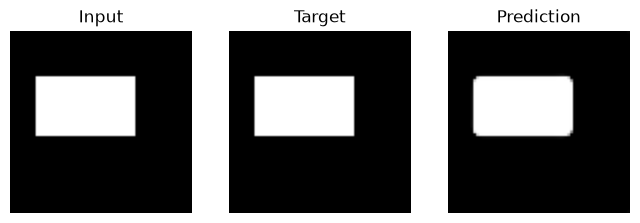

In [10]:
model.eval()
sample_img, sample_mask = dataset[0]
with torch.no_grad():
    pred = model(sample_img.unsqueeze(0)).squeeze().numpy()

plt.figure(figsize=(8,3))
plt.subplot(1,3,1); plt.imshow(sample_img.squeeze(), cmap='gray'); plt.title("Input"); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(sample_mask, cmap='gray'); plt.title("Target"); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(pred, cmap='gray'); plt.title("Prediction"); plt.axis('off')
plt.show()


### 셀 5 설명 — 예측 한 장 만들기

흐름: dataset[0](1,64,64) → unsqueeze(0)(1,1,64,64) → model(1,1,64,64) → squeeze()(64,64) → .numpy() 넘파이 배열

- `model.eval()` + `torch.no_grad()` — 평가 모드, 기울기 계산 끄기 (4장과 같음)
- `unsqueeze(0)` — 배치 차원 추가 (모델은 늘 배치로 받음) · `squeeze()` — 크기 1인 차원 모두 제거
- `pred` — 64×64 칸마다 0~1 확률이 든 넘파이 배열

- `subplot(1, 3, n)` — 1행 3열 중 n번째 칸
- `sample_img.squeeze()` — (1,64,64) → (64,64)
- Input = Target인 이유: 셀 1이 같은 배열을 줬기 때문
- 0 / 1로 보기: `plt.imshow(pred > 0.5, cmap='gray')`

## 과제 · 직접 바꿔 보기 — 실습 2

1. **num_epochs = 5 → 30**: 5 에폭에서 이미 Loss 0.1대 — 마지막 Loss와 그림을 같이 비교
2. **입력에 잡음 넣기**: 셀 1 `__getitem__`을 아래처럼 바꿔 입력은 noisy, 정답은 img 그대로 (들여쓰기 8칸 그대로. `astype(np.float32)`를 빼면 자료형 에러):
   ```python
   noisy = (img + 0.3 * np.random.randn(64, 64)).astype(np.float32)
   return torch.tensor(noisy).unsqueeze(0), torch.tensor(img)
   ```
3. **x_cat = x3**: 셀 2의 37번 줄을 이렇게 바꿔 스킵 연결 빼기. 21번 줄 `Conv2d(24,…)`도 `Conv2d(16,…)`로. 경계는?
4. **pred > 0.5**: 확률 지도를 0 / 1 마스크로 보기
5. **BCEWithLogitsLoss**: 셀 3 criterion 교체 · 셀 2의 41번 줄 sigmoid 빼기 · 셀 5의 4번 줄 `model(...)` → `torch.sigmoid(model(...))`. Loss 숫자는 거의 같음

- 셀 1~4를 바꿨으면 셀 2(모델)부터 다시 실행 (셀 1이면 셀 1부터). 셀 3을 건너뛰면 optimizer가 옛 모델을 붙잡고 있어 학습이 안 됨
- 과제 4처럼 셀 5만 바꿨으면 셀 5만 다시 실행

## 참고 · 실습 중 에러가 나면

| 에러 · 증상 | 원인 | 해결 |
|---|---|---|
| ValueError: Using a target size ... | 예측과 정답 모양이 다름 | `.squeeze(1)` 확인 |
| RuntimeError: Input type (double) and bias type (float) should be the same | 넘파이 float64가 모델에 들어감 | `.astype(np.float32)` |
| RuntimeError: ... expected input[8, 16, 64, 64] to have 24 channels, but got 16 channels instead | x_cat = x3인데 dec1은 24 그대로 | dec1 첫 Conv 입력 24 → 16 |